In [1]:
import requests, nltk, re
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)

# 1. سحب الأخبار
companies = {'AAPL': 'Apple', 'TSLA': 'Tesla', 'NVDA': 'Nvidia'}
headers = {'User-Agent': 'Mozilla/5.0'}
rows = []
for ticker, name in companies.items():
    url = f'https://news.google.com/rss/search?q={name}+stock&hl=en-US&gl=US&ceid=US:en'
    soup = BeautifulSoup(requests.get(url, headers=headers, timeout=15).text, 'xml')
    for item in soup.find_all('item'):
        rows.append({'ticker': ticker, 'date': item.pubDate.text, 'headline': item.title.text})
df = pd.DataFrame(rows)

# 2. تحليل المشاعر
sia = SentimentIntensityAnalyzer()
sia.lexicon.update({
    'record': 2.0, 'high': 1.5, 'rally': 2.5, 'surge': 2.5, 'soar': 2.5,
    'beat': 2.0, 'beats': 2.0, 'upgrade': 2.0, 'gain': 1.8, 'gains': 1.8,
    'falls': -2.0, 'fall': -2.0, 'drop': -2.0, 'plunge': -3.0, 'slump': -2.5,
    'sell-off': -2.5, 'selloff': -2.5, 'downgrade': -2.0, 'bearish': -2.0,
    'bullish': 2.0, 'miss': -2.0, 'misses': -2.0, 'lawsuit': -2.0, 'trillion': 0,
})
df['score'] = df['headline'].apply(lambda h: sia.polarity_scores(h)['compound'])
df['label'] = df['score'].apply(
    lambda s: 'positive' if s >= 0.05 else ('negative' if s <= -0.05 else 'neutral'))

# 3. تنظيف
df['date'] = pd.to_datetime(df['date'])
print('Duplicates:', df.duplicated(subset='headline').sum())
df = df.drop_duplicates(subset='headline')
df['headline_length'] = df['headline'].str.split().str.len()
df.to_csv('financial_news_sentiment.csv', index=False)

print(df.shape)
df.info()

Duplicates: 6
(296, 6)
<class 'pandas.core.frame.DataFrame'>
Index: 296 entries, 0 to 301
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   ticker           296 non-null    object        
 1   date             296 non-null    datetime64[ns]
 2   headline         296 non-null    object        
 3   score            296 non-null    float64       
 4   label            296 non-null    object        
 5   headline_length  296 non-null    int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 16.2+ KB


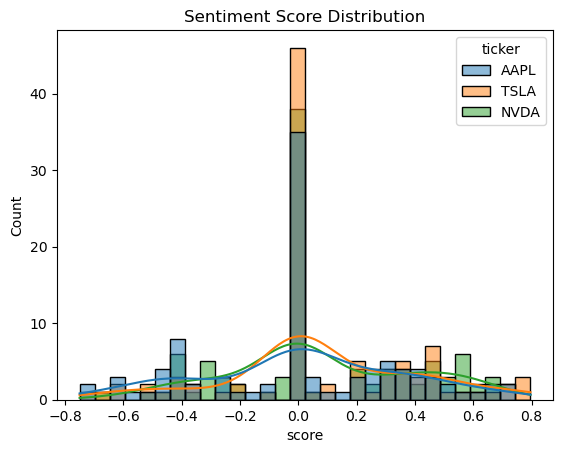

In [2]:
sns.histplot(data=df, x='score', hue='ticker', bins=30, kde=True)
plt.title('Sentiment Score Distribution'); plt.show()

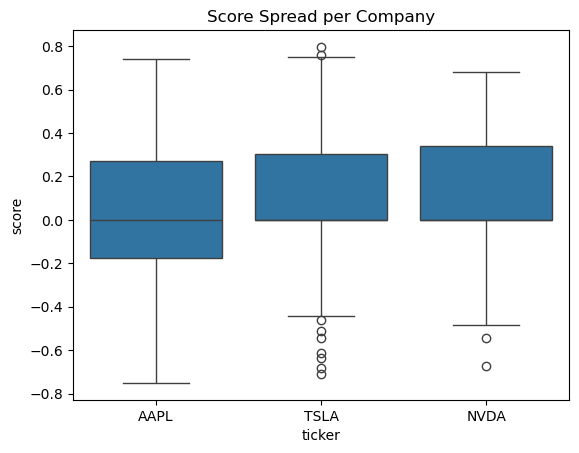

In [3]:
sns.boxplot(data=df, x='ticker', y='score')
plt.title('Score Spread per Company'); plt.show()

                 headline_length     score
headline_length         1.000000 -0.026927
score                  -0.026927  1.000000


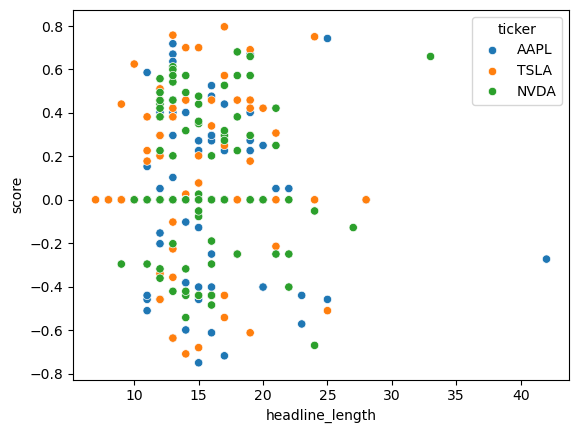

In [4]:
print(df[['headline_length', 'score']].corr())
sns.scatterplot(data=df, x='headline_length', y='score', hue='ticker')
plt.show()

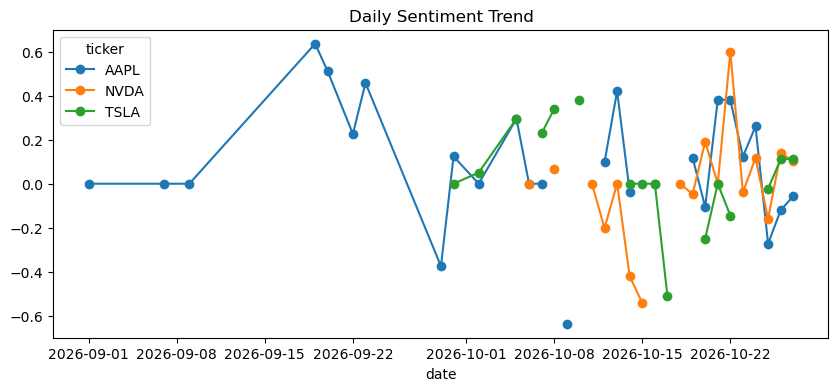

In [5]:
daily = df.groupby([df['date'].dt.date, 'ticker'])['score'].mean().unstack()
daily.plot(marker='o', figsize=(10, 4), title='Daily Sentiment Trend'); plt.show()

In [6]:
stop = {'the','a','an','and','of','to','in','for','on','is','as','at','with','by','from','its','it','stock','stocks','this','that','how','why'}
words = [w for h in df['headline'] for w in re.findall(r'[a-z]+', h.lower()) if w not in stop and len(w) > 2]
print(Counter(words).most_common(15))

[('yahoo', 103), ('finance', 103), ('tesla', 98), ('apple', 96), ('nvidia', 92), ('could', 38), ('spacex', 32), ('buy', 29), ('com', 27), ('motley', 25), ('fool', 25), ('here', 23), ('merger', 21), ('iphone', 20), ('barclays', 20)]


In [7]:
df['headline_clean'] = df['headline'].str.replace(r'\s-\s[^-]+$', '', regex=True)
stop |= {'yahoo','finance','com','tesla','apple','nvidia','could','here','buy'}
words = [w for h in df['headline_clean'] for w in re.findall(r'[a-z]+', h.lower()) if w not in stop and len(w) > 2]
print(Counter(words).most_common(15))

[('spacex', 32), ('merger', 21), ('iphone', 20), ('barclays', 20), ('after', 19), ('musk', 19), ('nvda', 19), ('says', 18), ('you', 18), ('meta', 18), ('will', 17), ('more', 16), ('now', 16), ('earnings', 14), ('prediction', 14)]


In [2]:
import pandas as pd
df = pd.read_csv('financial_news_sentiment.csv', parse_dates=['date'])
print(df.shape)
df.head(3)

(296, 6)


,ticker,date,headline,score,label,headline_length
0,AAPL,2026-10-26 18:02:00,Apple and Alphabet Stocks Look Vulnerable. Her...,-0.5994,negative,14
1,AAPL,2026-10-25 13:27:00,"In 1985, He Was Forced Out of the Company He F...",-0.2732,negative,42
2,AAPL,2026-10-27 12:02:18,Apple Could Lose Its $5 Trillion Valuation as ...,-0.4019,negative,15


In [3]:
g = df.groupby('ticker')['score']
stats = g.agg(n='count', mean='mean', median='median', std='std',
              q1=lambda s: s.quantile(0.25),
              q3=lambda s: s.quantile(0.75))
stats['iqr'] = stats['q3'] - stats['q1']
stats['pct_zero'] = g.apply(lambda s: (s == 0).mean() * 100)
stats['first_date'] = df.groupby('ticker')['date'].min().dt.date
stats['last_date'] = df.groupby('ticker')['date'].max().dt.date
print(stats.round(3).T)

ticker            AAPL        NVDA        TSLA
n                   99          98          99
mean             0.015       0.079       0.082
median             0.0         0.0         0.0
std              0.345       0.317       0.325
q1              -0.178         0.0         0.0
q3               0.272       0.342       0.302
iqr               0.45       0.342       0.302
pct_zero        35.354      38.776      46.465
first_date  2026-09-01  2026-10-06  2026-09-30
last_date   2026-10-27  2026-10-27  2026-10-27


ticker      AAPL  NVDA  TSLA
day                         
2026-10-13     3     1     0
2026-10-14     3     1     2
2026-10-15     0     1     2
2026-10-16     1     0     2
2026-10-17     0     0     1
2026-10-18     0     1     0
2026-10-19     3     2     0
2026-10-20     6     2     1
2026-10-21     1     2     3
2026-10-22     2     1     3
2026-10-23     9     3     0
2026-10-24     6     5     0
2026-10-25     1     7     6
2026-10-26    28    47    50
2026-10-27    15    19    19
Common window starts: 2026-10-06 | rows: 276
        count   mean  median    std
ticker                             
AAPL       85 -0.002     0.0  0.344
NVDA       98  0.079     0.0  0.317
TSLA       93  0.081     0.0  0.334


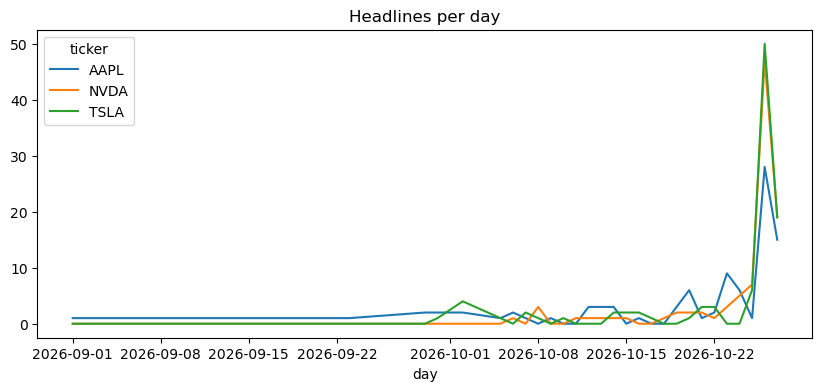

In [4]:
df['day'] = df['date'].dt.date
counts = df.groupby(['day', 'ticker']).size().unstack(fill_value=0)
print(counts.tail(15))
counts.plot(figsize=(10, 4), title='Headlines per day')

start = df.groupby('ticker')['date'].min().max()   # أحدث تاريخ بداية بين الشركات
common = df[df['date'] >= start]
print('Common window starts:', start.date(), '| rows:', len(common))
print(common.groupby('ticker')['score'].agg(['count', 'mean', 'median', 'std']).round(3))

In [5]:
import numpy as np
from scipy import stats as st

rng = np.random.default_rng(42)

def boot_ci(x, n=5000):
    x = np.asarray(x)
    means = [rng.choice(x, len(x), replace=True).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

for t, s in common.groupby('ticker')['score']:
    lo, hi = boot_ci(s)
    print(f'{t}: mean={s.mean():.3f}  95% CI [{lo:.3f}, {hi:.3f}]  n={len(s)}')

groups = [s.values for _, s in common.groupby('ticker')['score']]
H, p = st.kruskal(*groups)
n = sum(len(g) for g in groups); k = len(groups)
eta2 = (H - k + 1) / (n - k)   # حجم الأثر لـ Kruskal-Wallis
print(f'Kruskal-Wallis: H={H:.3f}, p={p:.4f}, eta^2={eta2:.4f}')

AAPL: mean=-0.002  95% CI [-0.076, 0.074]  n=85
NVDA: mean=0.079  95% CI [0.017, 0.144]  n=98
TSLA: mean=0.081  95% CI [0.014, 0.148]  n=93
Kruskal-Wallis: H=2.705, p=0.2586, eta^2=0.0026


In [6]:
df['headline_clean'] = df['headline'].str.replace(r'\s-\s[^-]+$', '', regex=True)

def summarize(d, name):
    gs = [s.values for _, s in d.groupby('ticker')['score']]
    if len(gs) < 3 or min(len(g) for g in gs) < 5:
        print(f'{name}: not enough data'); return
    H, p = st.kruskal(*gs)
    m = d.groupby('ticker')['score'].mean().round(3).to_dict()
    n = d.groupby('ticker').size().to_dict()
    print(f'{name}\n   n={n}\n   means={m}\n   KW p={p:.3f}\n')

summarize(df, 'All headlines')
summarize(common, 'Common window (from Oct 6)')
summarize(df[~df.duplicated(subset='headline_clean', keep=False)], 'No cross-ticker duplicates')
summarize(df[df['date'] < '2026-10-26'], 'Excluding Oct 26-27')
summarize(df[df['score'] != 0], 'Non-zero scores only')
summarize(df[df['score'].abs() >= 0.3], 'Strong scores only (|score| >= 0.3)')

All headlines
   n={'AAPL': 99, 'NVDA': 98, 'TSLA': 99}
   means={'AAPL': 0.015, 'NVDA': 0.079, 'TSLA': 0.082}
   KW p=0.405

Common window (from Oct 6)
   n={'AAPL': 85, 'NVDA': 98, 'TSLA': 93}
   means={'AAPL': -0.002, 'NVDA': 0.079, 'TSLA': 0.081}
   KW p=0.259

No cross-ticker duplicates
   n={'AAPL': 80, 'NVDA': 85, 'TSLA': 87}
   means={'AAPL': 0.025, 'NVDA': 0.099, 'TSLA': 0.097}
   KW p=0.364

Excluding Oct 26-27
   n={'AAPL': 56, 'NVDA': 32, 'TSLA': 30}
   means={'AAPL': 0.102, 'NVDA': -0.023, 'TSLA': 0.012}
   KW p=0.105

Non-zero scores only
   n={'AAPL': 64, 'NVDA': 60, 'TSLA': 53}
   means={'AAPL': 0.023, 'NVDA': 0.129, 'TSLA': 0.152}
   KW p=0.153

Strong scores only (|score| >= 0.3)
   n={'AAPL': 40, 'NVDA': 39, 'TSLA': 37}
   means={'AAPL': -0.02, 'NVDA': 0.207, 'TSLA': 0.177}
   KW p=0.119



In [7]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
base = SentimentIntensityAnalyzer()   # القاموس الافتراضي بدون إضافاتنا
print('fool / fools in default lexicon:', base.lexicon.get('fool'), base.lexicon.get('fools'))

df['headline_clean'] = df['headline'].str.replace(r'\s-\s[^-]+$', '', regex=True)
print(df['headline'].str.extract(r'\s-\s([^-]+)$')[0].value_counts().head(8))

df['raw_default'] = df['headline'].apply(lambda h: base.polarity_scores(h)['compound'])
df['clean_default'] = df['headline_clean'].apply(lambda h: base.polarity_scores(h)['compound'])
changed = df['raw_default'] != df['clean_default']
print('Scores that change when source name is removed:', changed.sum(), 'of', len(df))
print(df.loc[changed, ['headline', 'raw_default', 'clean_default']].head(8))

fool / fools in default lexicon: -1.9 -2.2
0
Yahoo Finance                101
The Motley Fool               25
Barron's                      13
CNBC                          12
24/7 Wall St.                 11
Investor's Business Daily      9
Barchart.com                   8
Investing.com                  8
Name: count, dtype: int64
Scores that change when source name is removed: 26 of 296
                                              headline  raw_default  \
7    Prediction: 3 Stocks That Will Be Worth More T...      -0.2500   
13   Apple vs. Taiwan Semiconductor: Which Tech Sto...       0.0000   
18   Prediction: Apple’s Stock Is Due for a Reality...      -0.4404   
50   Apple Joins Nvidia in the $5 Trillion Club. He...      -0.4404   
76   1 Reason Apple Could Outperform in 2027 - The ...      -0.4404   
77   1 Unstoppable Stock-Split Stock to Buy Before ...      -0.5719   
78   Should You Buy Apple Stock Now or Wait for a D...      -0.4404   
101  I Wouldn't Buy Tesla Stock Betting

In [8]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()
sia.lexicon.update({
    'record': 2.0, 'high': 1.5, 'rally': 2.5, 'surge': 2.5, 'soar': 2.5,
    'beat': 2.0, 'beats': 2.0, 'upgrade': 2.0, 'gain': 1.8, 'gains': 1.8,
    'falls': -2.0, 'fall': -2.0, 'drop': -2.0, 'plunge': -3.0, 'slump': -2.5,
    'sell-off': -2.5, 'selloff': -2.5, 'downgrade': -2.0, 'bearish': -2.0,
    'bullish': 2.0, 'miss': -2.0, 'misses': -2.0, 'lawsuit': -2.0, 'trillion': 0,
})
df['headline_clean'] = df['headline'].str.replace(r'\s-\s[^-]+$', '', regex=True)
df['score_raw'] = df['score']
df['score'] = df['headline_clean'].apply(lambda h: sia.polarity_scores(h)['compound'])
df['label'] = df['score'].apply(
    lambda s: 'positive' if s >= 0.05 else ('negative' if s <= -0.05 else 'neutral'))

print('Scores changed:', (df['score'] != df['score_raw']).sum(), 'of', len(df))
print(df.groupby('ticker').apply(lambda d: (d['score'] != d['score_raw']).sum()))
df.to_csv('financial_news_sentiment_clean.csv', index=False)

Scores changed: 26 of 296
ticker
AAPL     7
NVDA     9
TSLA    10
dtype: int64


/tmp/ipykernel_248/919373333.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df.groupby('ticker').apply(lambda d: (d['score'] != d['score_raw']).sum()))


In [9]:
g = df.groupby('ticker')['score']
summary = g.agg(n='count', mean='mean', median='median', std='std',
                q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75))
summary['iqr'] = summary['q3'] - summary['q1']
summary['pct_zero'] = g.apply(lambda s: (s == 0).mean() * 100)
print(summary.round(3).T)

common = df[df['date'] >= df.groupby('ticker')['date'].min().max()]
for t, s in common.groupby('ticker')['score']:
    lo, hi = boot_ci(s)
    print(f'{t}: mean={s.mean():.3f}  95% CI [{lo:.3f}, {hi:.3f}]  n={len(s)}')
H, p = st.kruskal(*[s.values for _, s in common.groupby('ticker')['score']])
print(f'Kruskal-Wallis (common window): p={p:.3f}\n')

summarize(df, 'All headlines')
summarize(common, 'Common window')
summarize(df[~df.duplicated(subset='headline_clean', keep=False)], 'No cross-ticker duplicates')
summarize(df[df['date'] < '2026-10-26'], 'Excluding Oct 26-27')
summarize(df[df['score'] != 0], 'Non-zero only')
summarize(df[df['score'].abs() >= 0.3], 'Strong scores only')

ticker      AAPL    NVDA    TSLA
n         99.000  98.000  99.000
mean       0.046   0.114   0.126
median     0.000   0.000   0.000
std        0.329   0.298   0.288
q1         0.000   0.000   0.000
q3         0.285   0.382   0.361
iqr        0.285   0.382   0.361
pct_zero  38.384  41.837  47.475
AAPL: mean=0.034  95% CI [-0.036, 0.103]  n=85
NVDA: mean=0.114  95% CI [0.056, 0.174]  n=98
TSLA: mean=0.129  95% CI [0.067, 0.187]  n=93
Kruskal-Wallis (common window): p=0.173

All headlines
   n={'AAPL': 99, 'NVDA': 98, 'TSLA': 99}
   means={'AAPL': 0.046, 'NVDA': 0.114, 'TSLA': 0.126}
   KW p=0.266

Common window
   n={'AAPL': 85, 'NVDA': 98, 'TSLA': 93}
   means={'AAPL': 0.034, 'NVDA': 0.114, 'TSLA': 0.129}
   KW p=0.173

No cross-ticker duplicates
   n={'AAPL': 80, 'NVDA': 85, 'TSLA': 87}
   means={'AAPL': 0.046, 'NVDA': 0.123, 'TSLA': 0.133}
   KW p=0.223

Excluding Oct 26-27
   n={'AAPL': 56, 'NVDA': 32, 'TSLA': 30}
   means={'AAPL': 0.125, 'NVDA': 0.006, 'TSLA': 0.041}
   KW p=0.133



In [10]:
sample = pd.concat([d.sample(34, random_state=42) for _, d in df.groupby('ticker')])
sample = sample.sample(frac=1, random_state=1)          # خلط الترتيب
out = sample[['ticker', 'headline_clean']].copy()
out['manual_label'] = ''
out.to_csv('manual_labeling_sample.csv', index_label='id')
print(len(out), 'headlines saved')

102 headlines saved
